# Notebook 04 — Modelado supervisado y SHAP

**Maestría en Data Mining · FCEyN UBA · Taller de Tesis I · Grupo G2**

Entrena 4 modelos sobre el dataset de usuarios (80.369 × 124) con CV estratificada k=5,
computa SHAP global y locales, mapea features a las dimensiones de Wang et al. (2024),
y muestra la comparativa con el modelo equivalente sobre dataset full (E2).

**Lógica:** importada de `scripts/modelado.py` y `scripts/decision_drop_auc.py`.

## 1. Setup

In [1]:
import sys
import importlib.util
import warnings
from pathlib import Path

warnings.filterwarnings("ignore")

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT / "scripts"))

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import Image, display

def load_module(name, path):
    spec = importlib.util.spec_from_file_location(name, path)
    mod = importlib.util.module_from_spec(spec)
    spec.loader.exec_module(mod)
    return mod

modelado = load_module("modelado", ROOT / "scripts" / "modelado.py")
auc_decision = load_module("auc_decision", ROOT / "scripts" / "decision_drop_auc.py")

plt.rcParams.update({"figure.dpi": 100, "font.size": 10})
print(f"TARGET_LABELS = {modelado.TARGET_LABELS}")

TARGET_LABELS = {1: 'Sin discrepancia', 0: 'Con discrepancia uso-actitud'}


## 2. Carga del dataset usuarios

In [2]:
df = modelado.cargar_dataset()
X, y, feature_cols = modelado.preparar_features(df)
print(f"\nFeatures: {len(feature_cols)}  ·  Filas: {len(X):,}  ·  Prevalencia target=1: {y.mean():.1%}")

Dataset: 80,369 × 124 cols
  Target=1 (Sin discrepancia): 78.5%
  Target=0 (Con discrepancia uso-actitud): 21.5%
Features: 123  |  Filas: 80,369

Features: 123  ·  Filas: 80,369  ·  Prevalencia target=1: 78.5%


## 3. Definición de los 4 modelos

In [3]:
models = modelado.definir_modelos(y)
list(models.keys())

scale_pos_weight (XGBoost) = 0.274


['Logistic Regression', 'Decision Tree', 'Random Forest', 'XGBoost']

## 4. Evaluación con CV estratificada k=5

In [4]:
cv_results, cv = modelado.evaluar_cv(models, X, y)

resumen = pd.DataFrame(cv_results).T.sort_values("ROC-AUC", ascending=False)
resumen_display = pd.DataFrame(index=resumen.index)
resumen_display["ROC-AUC"] = resumen.apply(lambda r: f"{r['ROC-AUC']:.4f} ± {r['ROC-AUC_std']:.4f}", axis=1)
resumen_display["F1-macro"] = resumen.apply(lambda r: f"{r['F1-macro']:.4f} ± {r['F1-macro_std']:.4f}", axis=1)
resumen_display.index.name = "Modelo"
resumen_display

  Logistic Regression... 

ROC-AUC=0.6317 ± 0.0049  F1=0.5392 ± 0.0030
  Decision Tree... 

ROC-AUC=0.6052 ± 0.0068  F1=0.5075 ± 0.0063
  Random Forest... 

ROC-AUC=0.6297 ± 0.0064  F1=0.5712 ± 0.0043
  XGBoost... 

ROC-AUC=0.6314 ± 0.0044  F1=0.5497 ± 0.0040


,ROC-AUC,F1-macro
Modelo,,
Logistic Regression,0.6317 ± 0.0049,0.5392 ± 0.0030
XGBoost,0.6314 ± 0.0044,0.5497 ± 0.0040
Random Forest,0.6297 ± 0.0064,0.5712 ± 0.0043
Decision Tree,0.6052 ± 0.0068,0.5075 ± 0.0063


**Lectura.** Los modelos lineales y no-lineales convergen (LogReg ≈ XGBoost ≈ 0,63 ROC-AUC). Esto indica que las relaciones intra-usuarios son mayormente lineales — no hay interacciones explotables por XGBoost.

## 5. Curvas ROC out-of-fold

  OOF predictions Logistic Regression... 

AUC=0.6316
  OOF predictions Decision Tree... 

AUC=0.6051
  OOF predictions Random Forest... 

AUC=0.6296
  OOF predictions XGBoost... 

AUC=0.6314


✓ /home/daro-m/Personal/maestria-taller-de-tesis-1/outputs/06_users_roc_curves.png


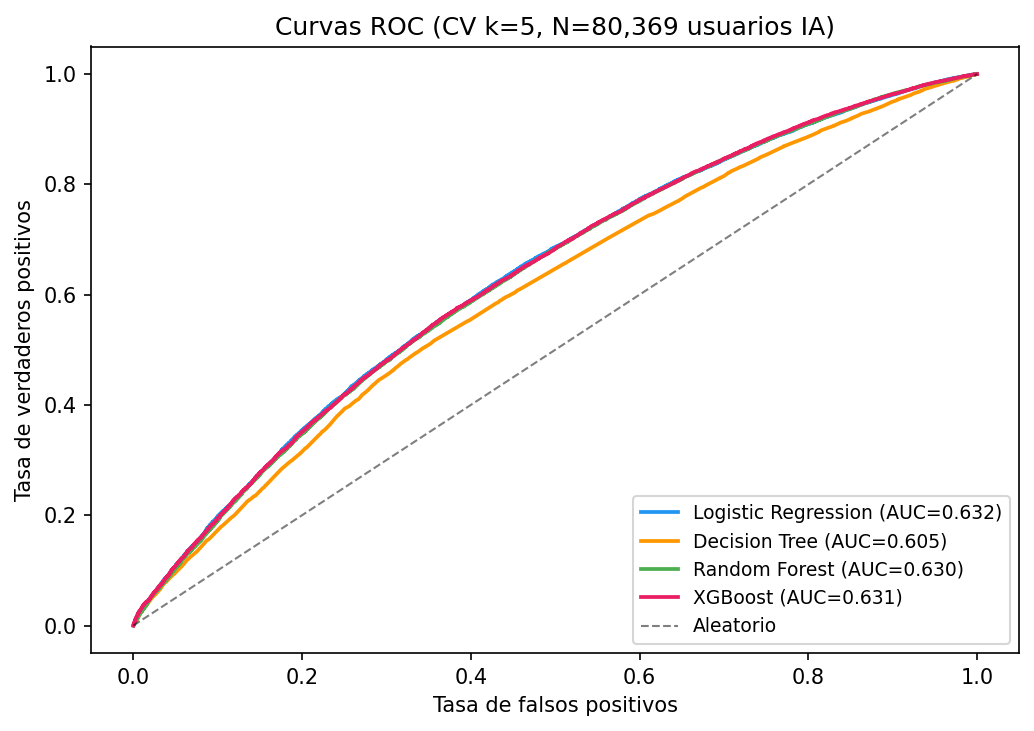

In [5]:
auc_oof = modelado.curvas_roc(models, X, y, cv)
display(Image(filename=str(ROOT / "outputs" / "06_users_roc_curves.png")))

## 6. Comparativa E2 vs E3 — drop de AUC

Reportamos el comportamiento del modelo sobre el dataset full (155k) y restricted (80k)
para entender qué cambia y por qué.

In [6]:
X_full, y_full, label_full = auc_decision.cargar_dataset(restricted=False)
res_full = auc_decision.evaluar_logreg(X_full, y_full, label_full)

X_res, y_res, label_res = auc_decision.cargar_dataset(restricted=True)
res_res = auc_decision.evaluar_logreg(X_res, y_res, label_res)

comp = pd.DataFrame({
    "Métrica": ["N", "Prevalencia target=1", "ROC-AUC", "PR-AUC clase 1", "PR-AUC clase 0 (discrepancia)"],
    "Full (155k)": [f"{res_full['n']:,}", f"{res_full['prevalence_target1']:.1%}",
                    f"{res_full['roc_auc']:.4f}", f"{res_full['pr_auc_pos']:.4f}", f"{res_full['pr_auc_neg']:.4f}"],
    "Restricted (80k)": [f"{res_res['n']:,}", f"{res_res['prevalence_target1']:.1%}",
                         f"{res_res['roc_auc']:.4f}", f"{res_res['pr_auc_pos']:.4f}", f"{res_res['pr_auc_neg']:.4f}"],
})
comp


=== Full (155k, sin restricción) (N=154,911, target=1: 40.7%) ===
  CV OOF predictions...


  ROC-AUC = 0.7070
  PR-AUC (clase 1, 'Sin discrepancia') = 0.6045
  PR-AUC (clase 0, 'Con discrepancia uso-actitud') = 0.7695
  Confusion matrix:
    Pred=0    Pred=1
     59182     32655  ← True=0
     21988     41086  ← True=1

=== Usuarios (E3, ~80k) (N=80,369, target=1: 78.5%) ===
  CV OOF predictions...


  ROC-AUC = 0.6316
  PR-AUC (clase 1, 'Sin discrepancia') = 0.8502
  PR-AUC (clase 0, 'Con discrepancia uso-actitud') = 0.3199
  Confusion matrix:
    Pred=0    Pred=1
     10480      6815  ← True=0
     26238     36836  ← True=1


,Métrica,Full (155k),Restricted (80k)
0,N,"154,911","80,369"
1,Prevalencia target=1,40.7%,78.5%
2,ROC-AUC,0.7070,0.6316
3,PR-AUC clase 1,0.6045,0.8502
4,PR-AUC clase 0 (discrepancia),0.7695,0.3199


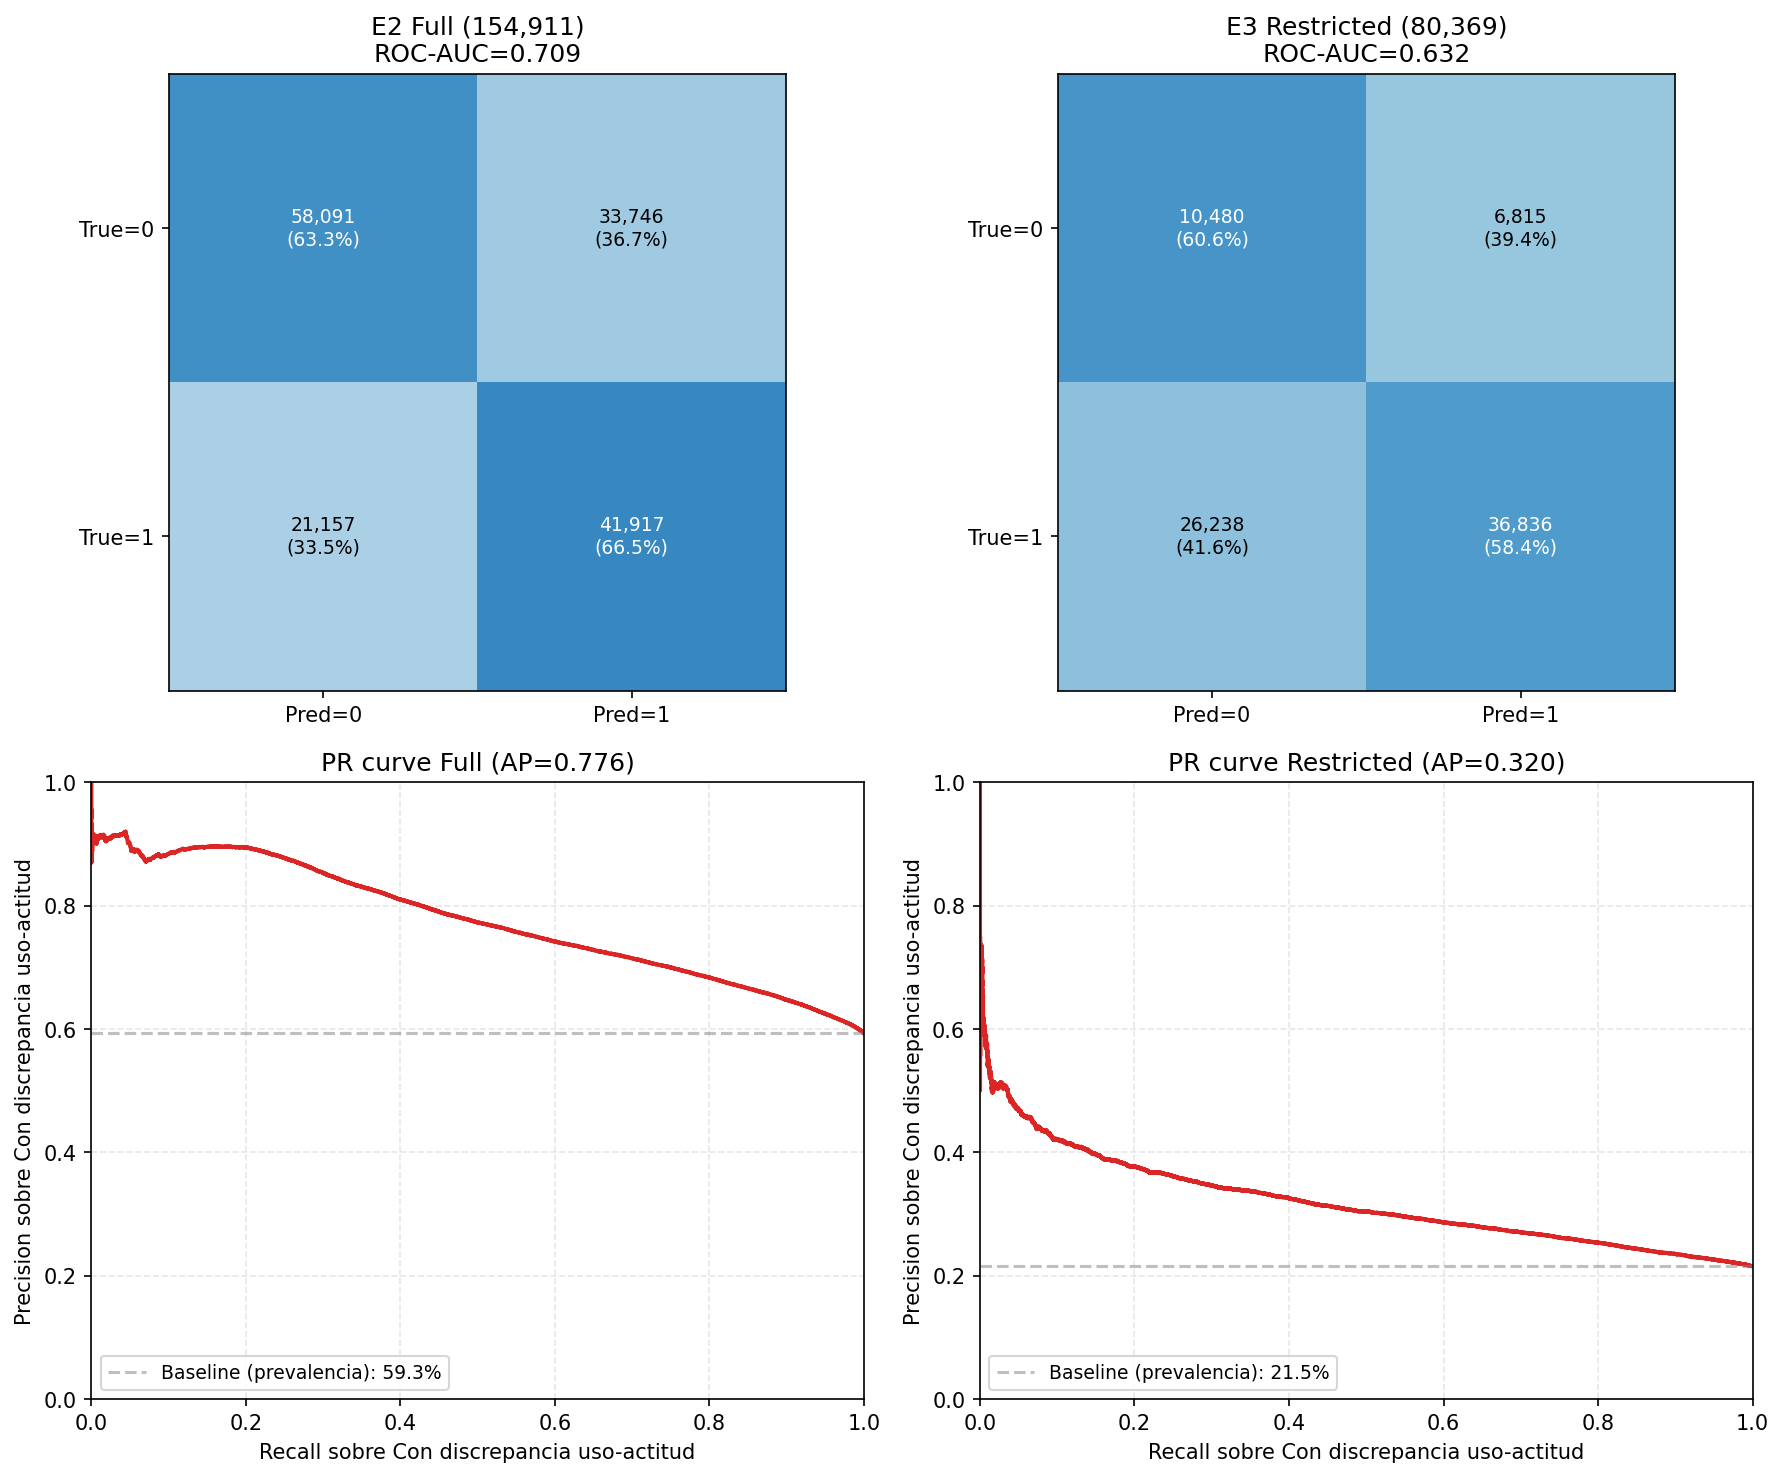

In [7]:
display(Image(filename=str(ROOT / "outputs" / "07_decision_drop_auc.png")))

**Lectura honesta.**
- El drop de ROC-AUC (0,71 → 0,63) **no es un bug** — es la consecuencia de restringir a usuarios.
- **PR-AUC sobre clase 0 cae de 0,776 a 0,320** — más significativo que ROC-AUC, mostrando que la capacidad predictiva sobre el subgrupo de interés sí baja.
- Lift sobre baseline aleatorio: +18,3 pp (full) → +10,5 pp (restricted). Señal real pero más modesta.
- La elección es la **pregunta epistemológicamente correcta** (learned trust solo aplica a quienes tuvieron exposición), a costo de un modelo más modesto. Documento completo: `resultados/decision_drop_auc.md`.

## 7. SHAP global — interpretación del modelo

In [8]:
df_results = pd.DataFrame(cv_results).T.sort_values("ROC-AUC", ascending=False)
best_name = df_results.index[0]
shap_name, top_features, X_bg, shap_values, fitted_model = modelado.shap_analysis(best_name, models, X, y)

print(f"\nModelo SHAP: {shap_name}")
print(f"\nTop 15 features por |SHAP| medio:")
top_features.head(15).round(4)

Modelo SHAP: Random Forest
  Entrenando en dataset completo... 

OK.


  shap_values shape: (1000, 123)

Top 10 features por |SHAP|:
survey_year               0.038265
env_Visual_Studio_Code    0.020342
Employment_Other          0.011036
Region_EU                 0.009697
Region_ASIA               0.008846
env_Neovim                0.008682
lang_Rust                 0.007435
lang_C                    0.007159
lang_count                0.006413
plat_Firebase             0.005936



✓ /home/daro-m/Personal/maestria-taller-de-tesis-1/outputs/06_users_shap_global.png


✓ /home/daro-m/Personal/maestria-taller-de-tesis-1/outputs/06_users_shap_bar.png

Modelo SHAP: Random Forest

Top 15 features por |SHAP| medio:


survey_year                     0.0383
YearsCode                       0.0045
YearsCodePro                    0.0037
WorkExp                         0.0030
EdLevel                         0.0015
OrgSize                         0.0027
lang_JavaScript                 0.0029
lang_HTML_CSS                   0.0013
lang_SQL                        0.0009
lang_Python                     0.0043
lang_TypeScript                 0.0011
lang_Bash_Shell_(all_shells)    0.0034
lang_Java                       0.0019
lang_C#                         0.0016
lang_PHP                        0.0006
dtype: float64

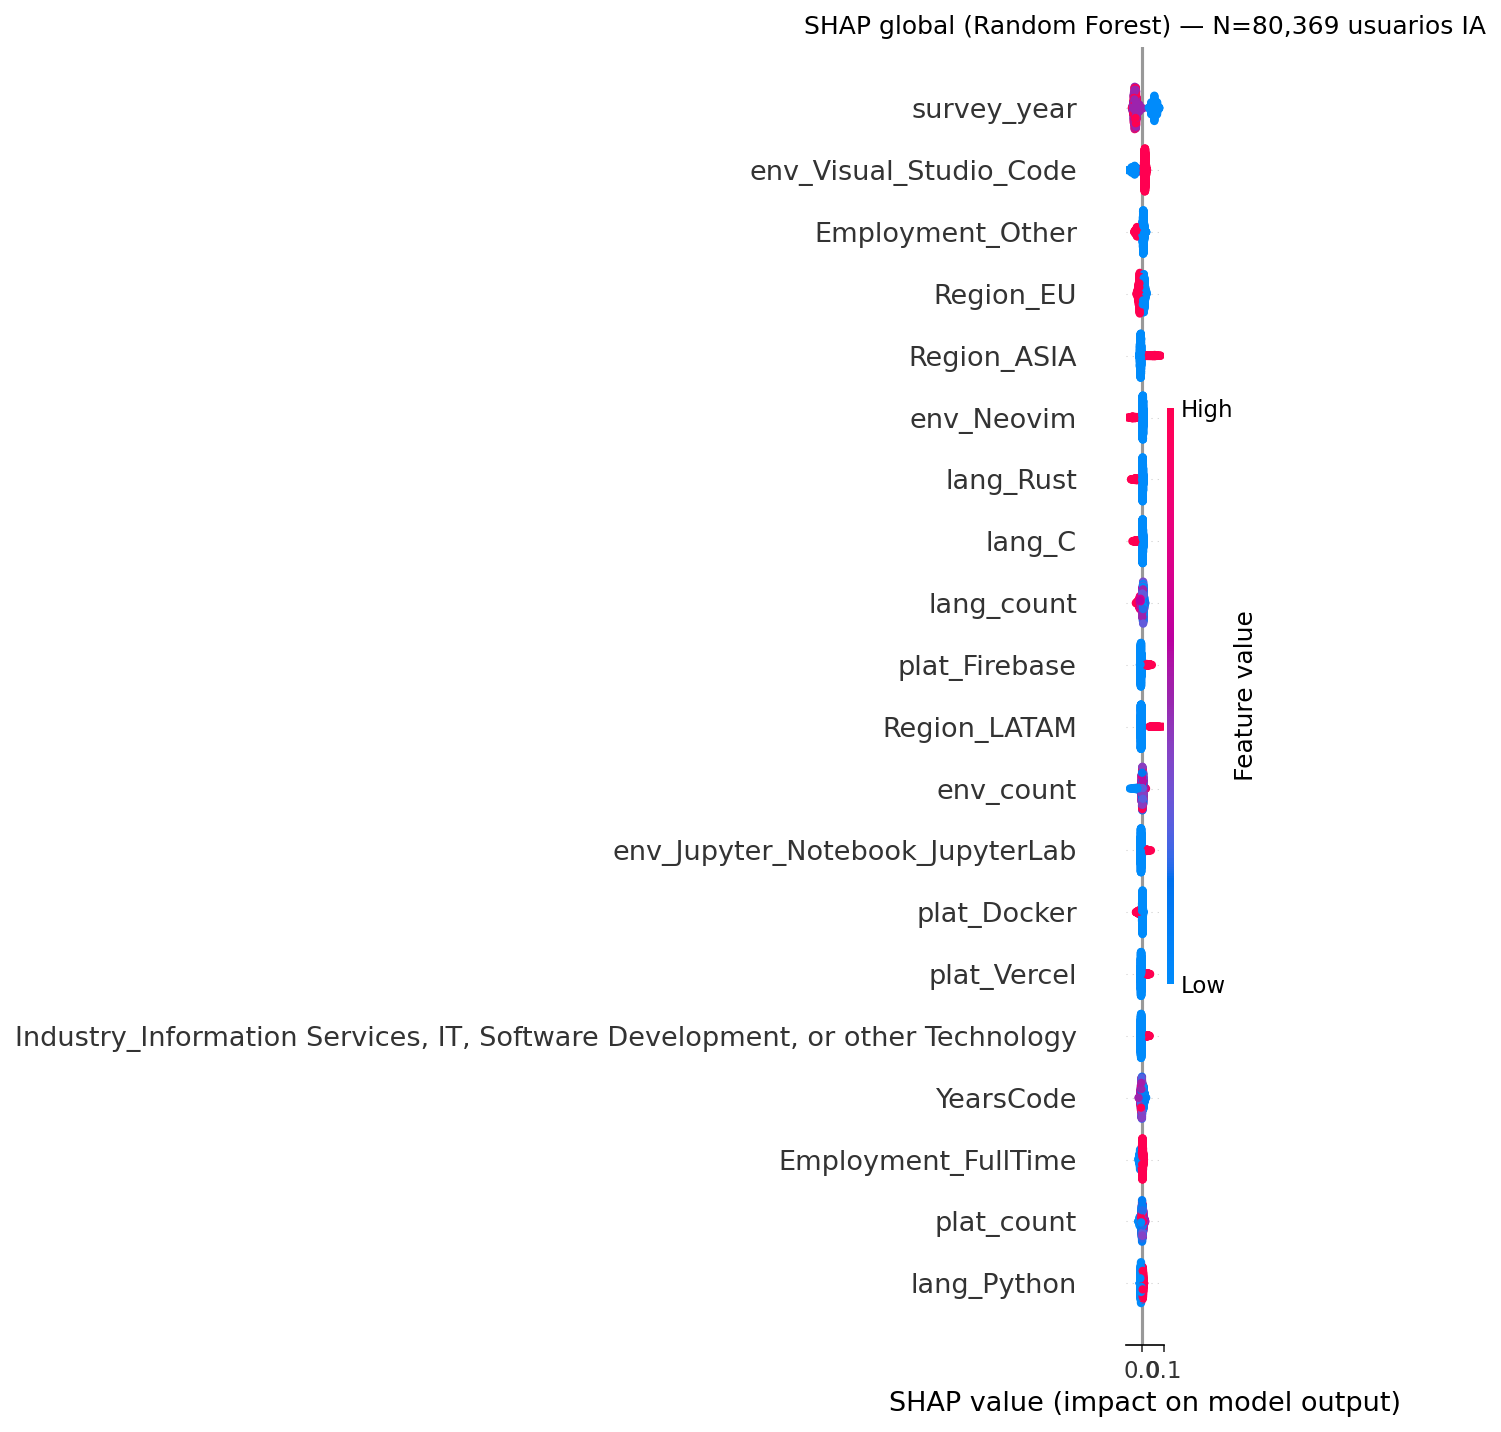

In [9]:
display(Image(filename=str(ROOT / "outputs" / "06_users_shap_global.png")))

## 8. SHAP local — 3 casos contrastantes

In [10]:
cases = modelado.shap_local_cases(fitted_model, X_bg, shap_values, top_features)
for label, idx, prob in cases:
    print(f"  Caso {label}: fila bg #{idx} · P(target=0) = {prob:.3f}")

✓ /home/daro-m/Personal/maestria-taller-de-tesis-1/outputs/06_users_shap_local.png
  Caso A — Discrepante (target=0): fila bg #232 · P(target=0) = 0.767
  Caso B — Sin discrepancia (target=1): fila bg #851 · P(target=0) = 0.176
  Caso C — Borderline: fila bg #501 · P(target=0) = 0.500


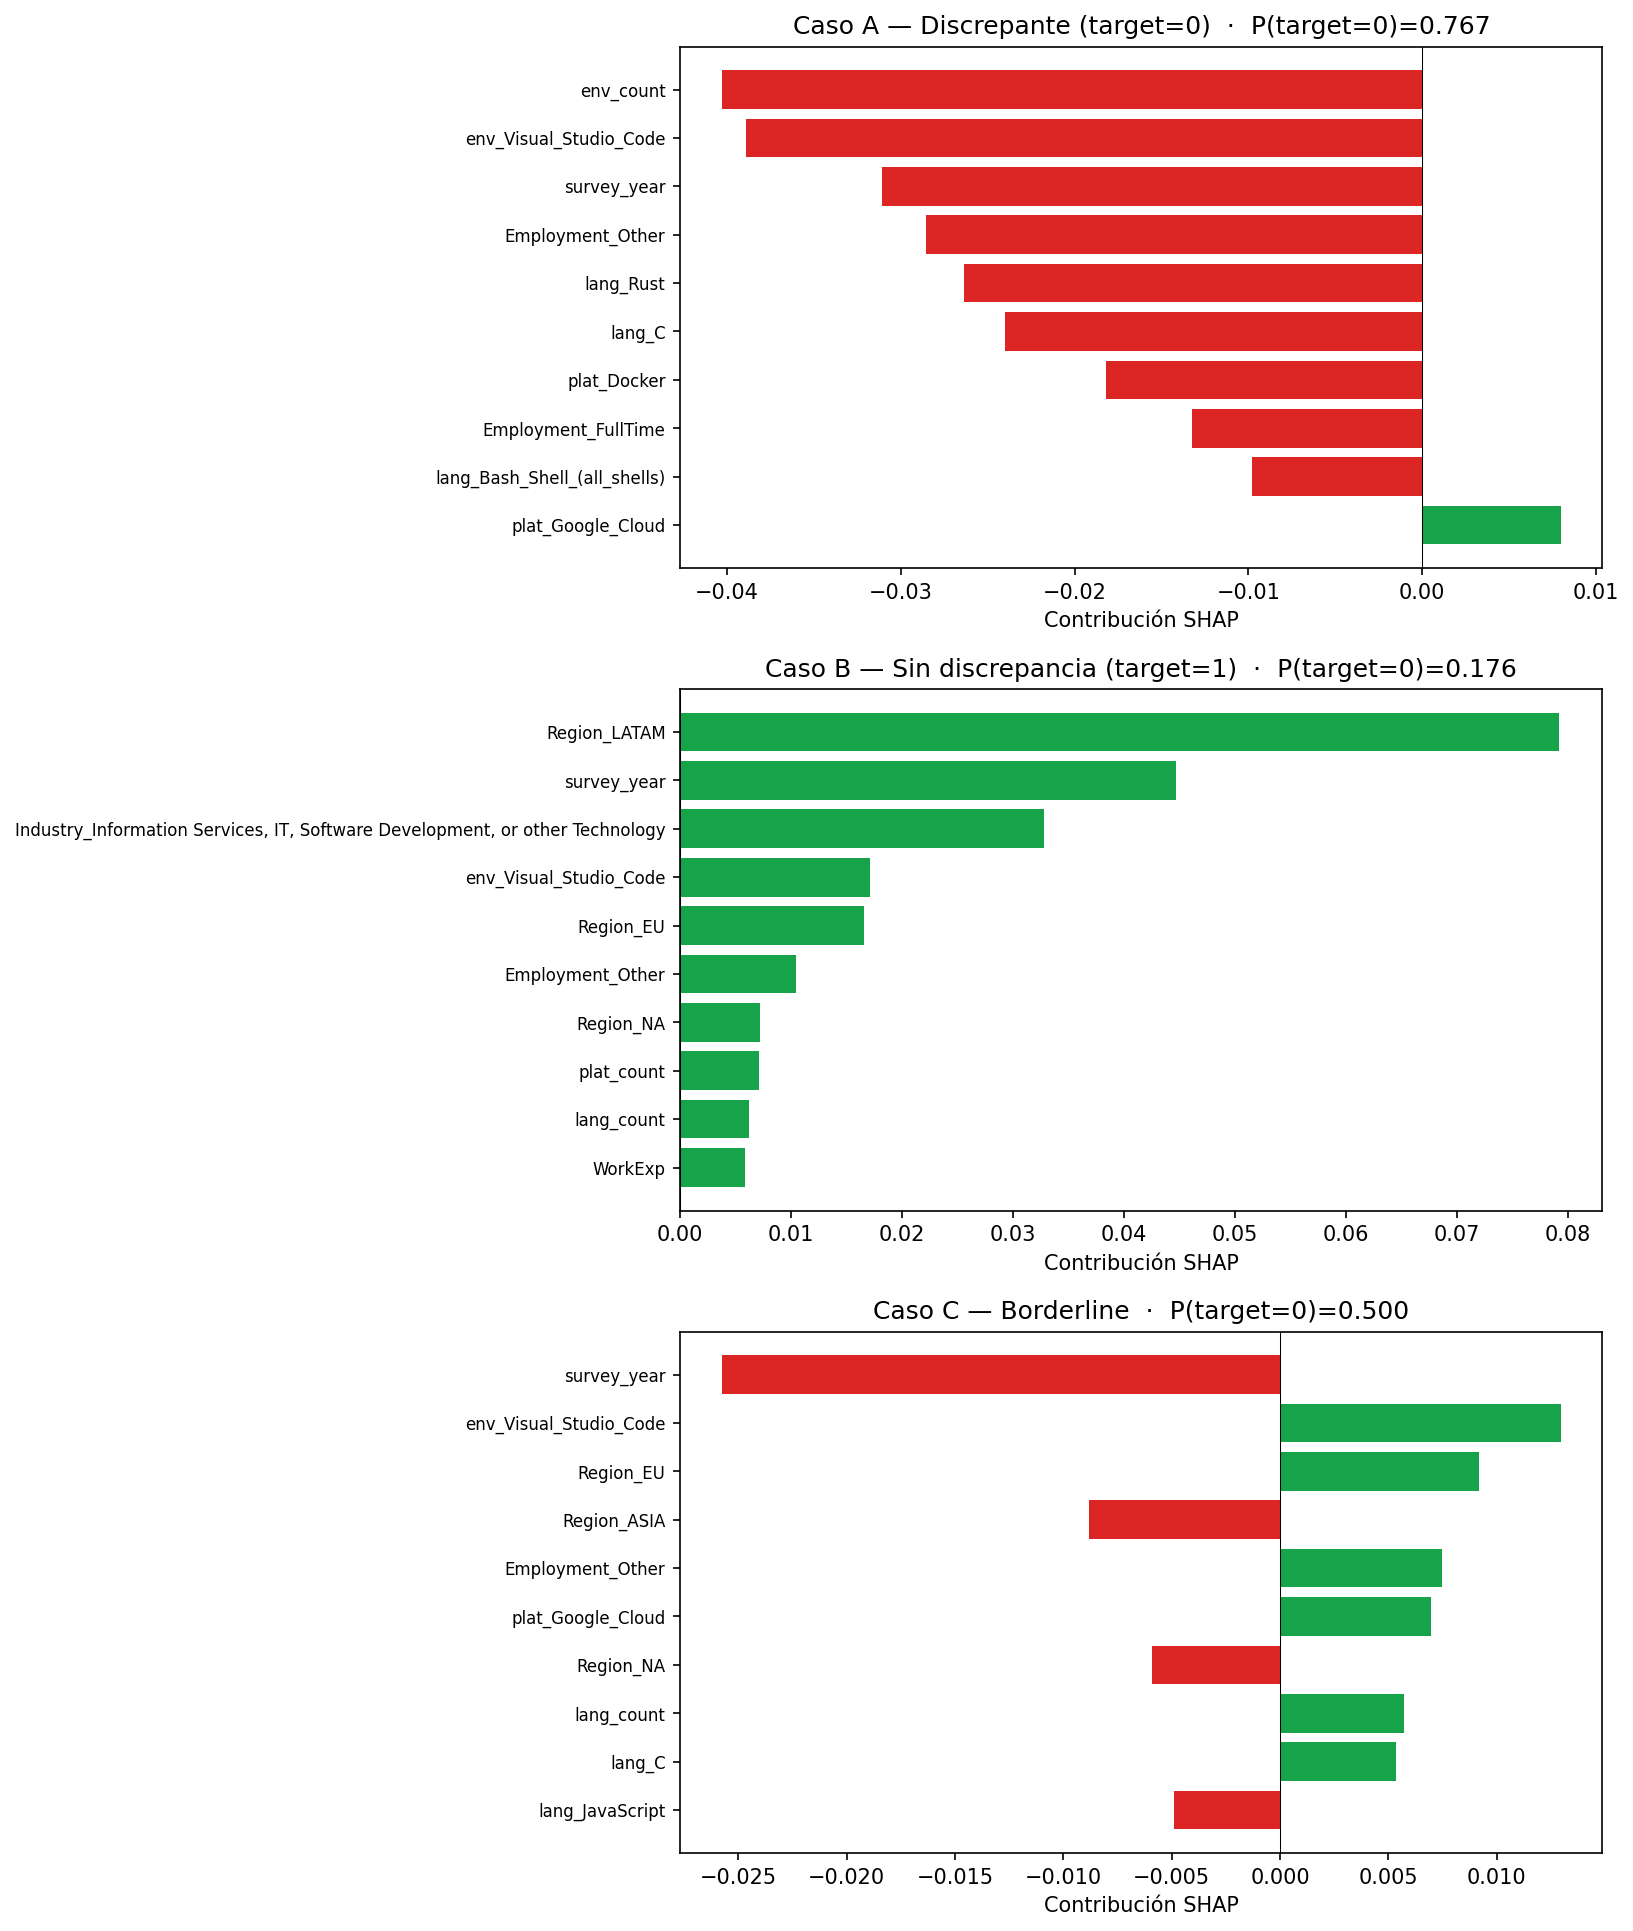

In [11]:
display(Image(filename=str(ROOT / "outputs" / "06_users_shap_local.png")))

## 9. Mapeo Wang — ability / integrity / benevolence

Categorizamos cada feature según las dimensiones de Wang et al. (2024).

In [12]:
wang_summary, df_wang = modelado.wang_mapping(top_features)
wang_summary.round(4)


Distribución por dimensión Wang:
                  sum  count      mean
dim                                   
Ability      0.169173     80  0.002115
Integrity    0.064492     14  0.004607
Benevolence  0.037145     29  0.001281


✓ /home/daro-m/Personal/maestria-taller-de-tesis-1/outputs/06_users_shap_wang_mapping.png


,sum,count,mean
dim,,,
Ability,0.1692,80,0.0021
Integrity,0.0645,14,0.0046
Benevolence,0.0371,29,0.0013


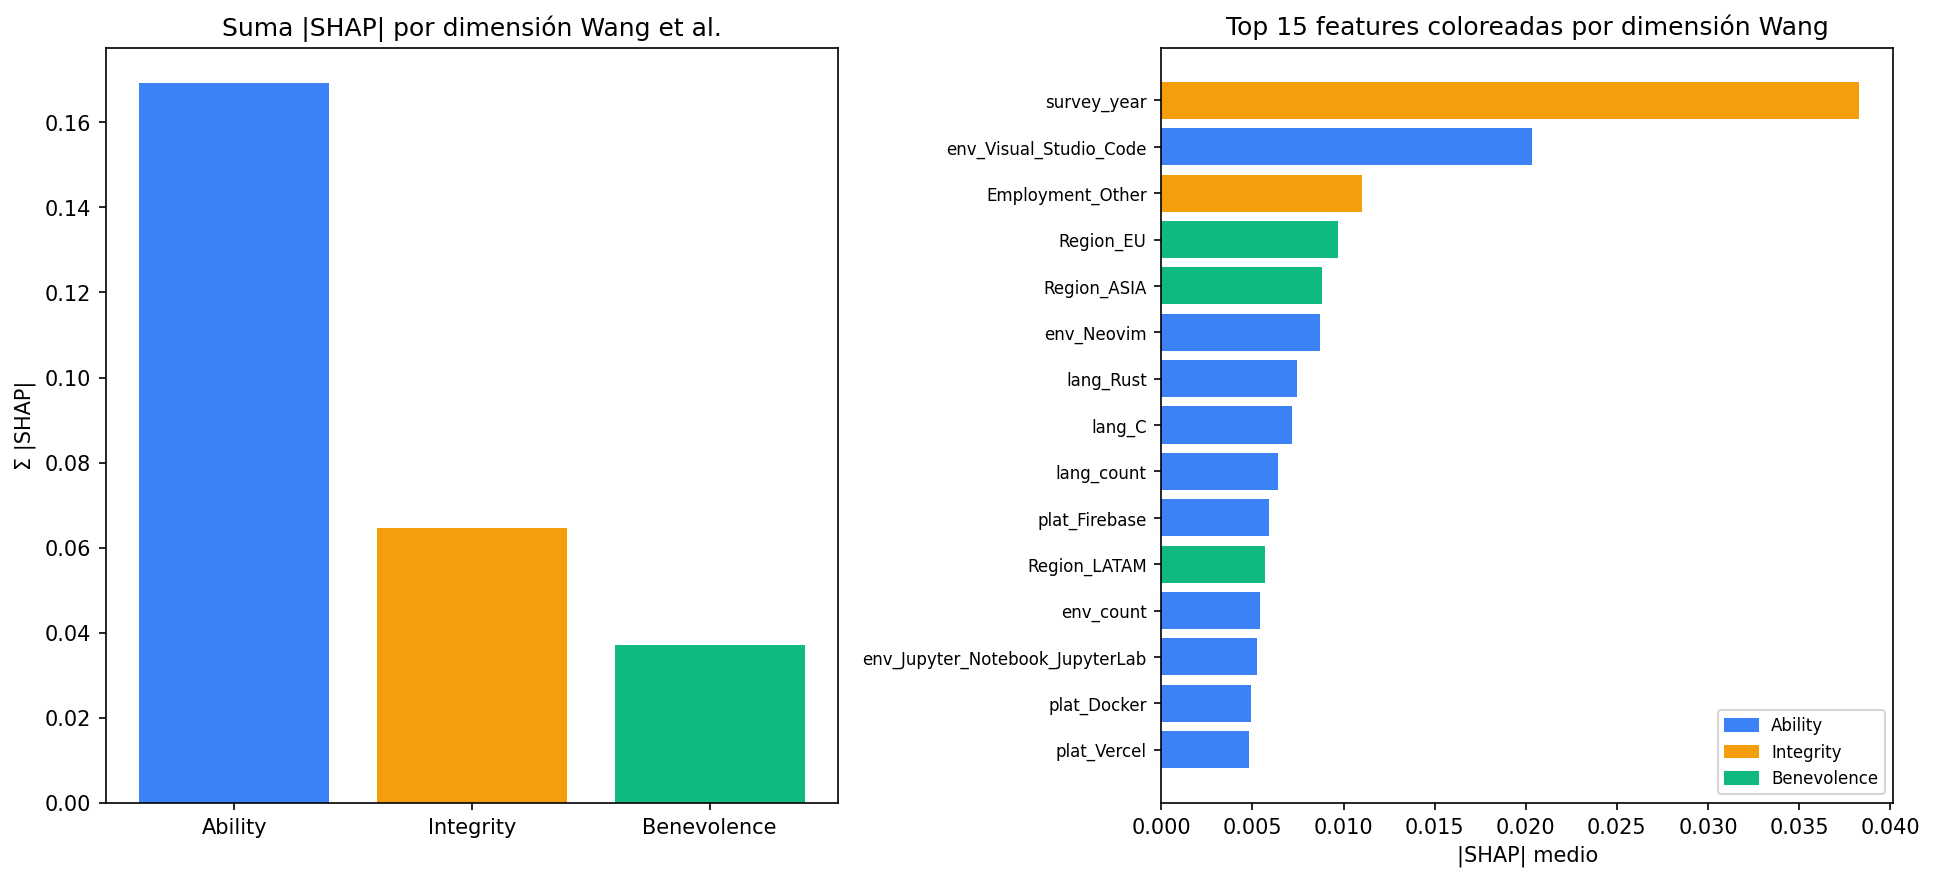

In [13]:
display(Image(filename=str(ROOT / "outputs" / "06_users_shap_wang_mapping.png")))

**Lectura.** Ability domina (53 % del peso predictivo agregado, 80 features). Wang et al. (2024) identificó estas dimensiones con N=29 entrevistas; aquí las cuantificamos sobre N=80.369.

## 10. Resumen

| Hallazgo | Valor |
|---|---|
| Mejor modelo (ROC-AUC) | **LogReg = 0,632 ± 0,005** |
| XGBoost | 0,631 (empate) |
| PR-AUC clase 0 (discrepancia) | 0,320 (lift +10,5 pp sobre baseline) |
| Top feature SHAP | `survey_year` (0,038) |
| Ability / Integrity / Benevolence | 53 % / 20 % / 12 % |
| Threshold óptimo F1 detectar discrepancia | 0,479 |

**Próximos pasos:**
- Confirmar label final del target con la profesora.
- Threshold tuning explícito para detección de discrepancia (~precision 0,28, recall 0,67).
- Integrar narrativa en E3 §7 (Modelado) y §8 (Discusión).

## 11. Análisis temporal — Capas A, B y C

El feedback de pre-validación E3 señaló que la adopción de IA es un fenómeno que **cambia rápido**
y conviene mirar los años por separado. Este análisis replica y extiende el modelo pooled en tres capas:

| Capa | Descripción | Script |
|---|---|---|
| **A — Descriptivo por año** | Tasa base, H1 seniority y H2 DevType estratificados | `scripts/temporal.py` |
| **B — Within-year** | LogReg + XGBoost entrenados y evaluados dentro de cada año; coeficientes con signo | `scripts/modelado_temporal.py` |
| **C — Validación forward** | Train año pasado → test año futuro; mide concept drift empíricamente | `scripts/modelado_temporal.py` |

**Nota metodológica:** las tres capas usan las mismas 91 features comunes (varianza > 0 en los 3 años,
`survey_year` excluida). El pooled incluye `survey_year` como feature adicional.

In [ ]:
temporal = load_module("temporal", ROOT / "scripts" / "temporal.py")
mod_temp = load_module("modelado_temporal", ROOT / "scripts" / "modelado_temporal.py")

df_users = temporal.cargar()
feature_cols = mod_temp.common_features(df_users)
print(f"Dataset usuarios: {df_users.shape[0]:,} filas")
print(f"Features comunes a los 3 años (sin survey_year): {len(feature_cols)}")

### Capa A — Descriptivo por año

**Tasa base de discrepancia uso-actitud por año (subpoblación usuarios):**

| Año | % Discrepancia | N total | N discrepantes |
|-----|---------------|---------|----------------|
| 2023 | 15.3% | 29,697 | 4,553 |
| 2024 | 23.4% | 29,638 | 6,943 |
| 2025 | 27.6% | 21,034 | 5,799 |
| **Pooled** | **21.5%** | **80,369** | **17,295** |

La discrepancia crece +12.3 pp de 2023 a 2025 — el fenómeno se acentúa entre usuarios activos.

**H1 — Seniority × año (gap juniors → seniors):**
- 2023: +1.7 pp (no monotónica)  ·  2024: +0.8 pp (no monotónica)  ·  2025: +8.2 pp (monotónica)
- Comparar con full dataset (E2): +22.9 pp (2023). La paradoja de seniority era principalmente un efecto usuarios/no-usuarios, no intra-usuarios.

**H2 — DevType × año:** Embedded (20→32→36%), Student (19→26→38%) lideran discrepancia. DS/ML (12→15→21%) la menor. Orden relativo estable entre olas.

In [ ]:
tabla_base, fig_base = temporal.tasa_base_por_anio(df_users)
tabla_h1, fig_h1 = temporal.h1_temporal_usuarios(df_users)
tabla_h2, fig_h2 = temporal.h2_temporal_usuarios(df_users)

display(Image(filename=str(ROOT / "outputs" / "08_temporal_tasa_base.png")))
display(Image(filename=str(ROOT / "outputs" / "08_temporal_H1_seniority.png")))
display(Image(filename=str(ROOT / "outputs" / "08_temporal_H2_devtype.png")))

### Capa B — Modelos within-year (LogReg + XGBoost)

**Comparación de AUC — pooled vs. within-year (LogReg, CV k=5):**

| Condición | ROC-AUC | PR-AUC (clase minoritaria) | N |
|---|---|---|---|
| Pooled (con survey_year) | **0.6313** | 0.3198 | 80,369 |
| Pooled (sin survey_year) | 0.6174 | 0.3089 | 80,369 |
| Within-year 2023 | 0.5770 | 0.1906 | 29,697 |
| Within-year 2024 | 0.5994 | 0.3096 | 29,638 |
| Within-year 2025 | **0.6392** | **0.3910** | 21,034 |

*PR-AUC calculado para clase minoritaria (discrepancia, target=0). Baseline: tasa base por año (≈15-28%).*

**Interpretación:** el AUC within-year crece de 0.577 (2023) a 0.639 (2025). En 2023 el modelo apenas supera el baseline de PR-AUC, en 2025 lo supera claramente. El perfil predice mejor cuando el fenómeno está más maduro.

**Efecto de survey_year:** diferencia pooled con vs sin = +0.014 pp — pequeña; la mayor parte del AUC la aporta el perfil del desarrollador, no el año.

**Coeficientes LogReg con signo — features más destacadas:**
- `YearsCode` / `YearsCodePro`: ~0 en 2023-24, saltan a ±1.1 en 2025 (posible efecto de la ola 2025 que refuerza la paradoja de seniority)
- `env_count`: negativo en 2023-24 (más herramientas = menos discrepancia), se invierte (+0.67) en 2025
- `env_Visual_Studio_Code`: positivo y estable en los 3 años (top SHAP en 2023 y 2025)
- 45 de 91 features cambian de signo entre algún par de años → el fenómeno evoluciona en su estructura lineal

In [ ]:
auc_results = mod_temp.comparar_auc(df_users, feature_cols)
xgb_results = mod_temp.xgb_check_por_anio(df_users, feature_cols)
tabla_coef = mod_temp.coeficientes_por_anio(df_users, feature_cols)

display(Image(filename=str(ROOT / "outputs" / "08_temporal_auc_comparison.png")))
display(Image(filename=str(ROOT / "outputs" / "08_temporal_coef_heatmap.png")))
display(Image(filename=str(ROOT / "outputs" / "08_temporal_shap_por_anio.png")))

### Capa C — Validación temporal forward (concept drift)

**Esquema:** train en año(s) pasado(s) → test en año futuro. Mismas 91 features en train y test.

| Esquema | ROC-AUC forward | ROC-AUC within (ref.) | Δ drift | PR-AUC(min) |
|---|---|---|---|---|
| 2023 → 2024 | 0.5809 | 0.5994 | **−1.9 pp** | 0.2996 |
| 2024 → 2025 | 0.6061 | 0.6392 | **−3.3 pp** | 0.3588 |
| 2023+24 → 2025 | 0.6120 | 0.6392 | **−2.7 pp** | 0.3708 |

**Lectura del drift:** hay concept drift medible y creciente entre olas.
- 2023→2024: caída de −1.9 pp vs. within-2024.
- 2024→2025: caída de −3.3 pp vs. within-2025 — el drift **se acelera**.
- Combinar 2023+2024 como train reduce levemente el drift (−2.7 pp), pero no lo elimina.

**Implicancia central:** el AUC bajo (~0.63) no es solo una limitación del modelo — es también evidencia de que el fenómeno está evolucionando. Un modelo entrenado en el pasado transfiere peor porque la discrepancia uso-actitud tiene dinámica temporal propia. Esto conecta directamente con Lee & See (2004): la confianza se actualiza continuamente con la experiencia, y el perfil estático del desarrollador no captura esa dinámica.

In [ ]:
forward_results = {
    "fwd_23_24":    mod_temp.evaluar_forward(df_users, feature_cols, [2023], 2024),
    "fwd_24_25":    mod_temp.evaluar_forward(df_users, feature_cols, [2024], 2025),
    "fwd_2324_25":  mod_temp.evaluar_forward(df_users, feature_cols, [2023, 2024], 2025),
}
display(Image(filename=str(ROOT / "outputs" / "08_temporal_validation.png")))

### Resumen comparativo — pooled vs. por-año vs. forward

| Análisis | ROC-AUC | PR-AUC(min) | Interpretación |
|---|---|---|---|
| **Pooled (con year)** | 0.631 | 0.320 | Referencia principal E3 |
| **Pooled (sin year)** | 0.617 | 0.309 | Survey_year aporta +1.4 pp |
| **Within 2023** | 0.577 | 0.191 | Año de adopción temprana, señal débil |
| **Within 2024** | 0.599 | 0.310 | Señal moderada |
| **Within 2025** | 0.639 | 0.391 | Señal más fuerte, fenómeno más maduro |
| **Forward 2023→24** | 0.581 | 0.300 | Drift −1.9 pp |
| **Forward 2024→25** | 0.606 | 0.359 | Drift −3.3 pp (aceleración) |
| **Forward 2023+24→25** | 0.612 | 0.371 | Drift −2.7 pp (más train ayuda poco) |

**Conclusión:** el AUC bajo no es un defecto del método — es una medida de la dificultad intrínseca del problema y de la inestabilidad temporal del fenómeno. El perfil estático del desarrollador predice la discrepancia uso-actitud con señal real pero modesta, y esa señal decrece cuando se intenta transferir hacia el futuro.

Para la discusión de E3: citar §8 (concept drift como resultado, no limitación) y §10 (validación temporal como respuesta empírica al feedback de la profesora sobre la adopción como fenómeno dinámico).

Documentación completa: `resultados/resultados_temporal_usuarios.md` y `resultados/resultados_modelado_temporal.md`.